<a href="https://colab.research.google.com/github/aisyaaaaaaa/facial-emotion-detection/blob/main/face_emotion_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install dan import library

In [ ]:
!pip -q install kagglehub scikit-learn seaborn

In [ ]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
IMG_SIZE = (48, 48)
BATCH_SIZE = 64
EPOCHS = 10

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Download dataset langsung dari Kaggle

In [ ]:
# Dataset publik. Jika KaggleHub meminta autentikasi pada akun/environment kamu,
# ikuti petunjuk KaggleHub untuk menghubungkan Kaggle API token melalui Colab Secrets.
DATASET_HANDLE = "ananthu017/emotion-detection-fer"
DATASET_PATH = Path(kagglehub.dataset_download(DATASET_HANDLE))

print("Dataset tersimpan di:", DATASET_PATH)
print("Isi folder utama:")
for item in DATASET_PATH.iterdir():
    print("-", item.name, "(folder)" if item.is_dir() else "(file)")

100%|██████████| 65.2M/65.2M [00:00<00:00, 171MB/s]

Extracting files...


Dataset tersimpan di: /root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1
Isi folder utama:
- train (folder)
- test (folder)


In [ ]:
def find_named_dir(root: Path, name: str):
    matches = [p for p in root.rglob("*") if p.is_dir() and p.name.lower() == name.lower()]
    return matches

train_matches = find_named_dir(DATASET_PATH, "train")
test_matches = find_named_dir(DATASET_PATH, "test")

print("Kandidat train:", train_matches[:10])
print("Kandidat test :", test_matches[:10])

if not train_matches or not test_matches:
    print("\\nStruktur direktori dataset (maksimal 3 tingkat):")
    for root, dirs, files in os.walk(DATASET_PATH):
        depth = len(Path(root).relative_to(DATASET_PATH).parts)
        if depth <= 3:
            print("  " * depth + Path(root).name + "/")
    raise FileNotFoundError(
        "Folder train/test tidak ditemukan otomatis. Periksa struktur di atas, "
        "lalu tetapkan TRAIN_DIR dan TEST_DIR secara manual."
    )

# Gunakan kandidat dengan direktori kelas terbanyak di dalamnya
def class_subdir_count(folder):
    return sum(1 for p in folder.iterdir() if p.is_dir())

TRAIN_DIR = max(train_matches, key=class_subdir_count)
TEST_DIR = max(test_matches, key=class_subdir_count)

print("\\nTRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)
print("Subfolder kelas train:", [p.name for p in TRAIN_DIR.iterdir() if p.is_dir()])

Kandidat train: [PosixPath('/root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1/train')]
Kandidat test : [PosixPath('/root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1/test')]
\nTRAIN_DIR: /root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1/train
TEST_DIR : /root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1/test
Subfolder kelas train: ['surprised', 'fearful', 'happy', 'neutral', 'angry', 'sad', 'disgusted']


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Urutan kelas:", class_names)
print("Jumlah kelas:", num_classes)

if num_classes < 2:
    raise ValueError("Folder train harus memiliki minimal dua subfolder kelas.")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.
Urutan kelas: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Jumlah kelas: 7


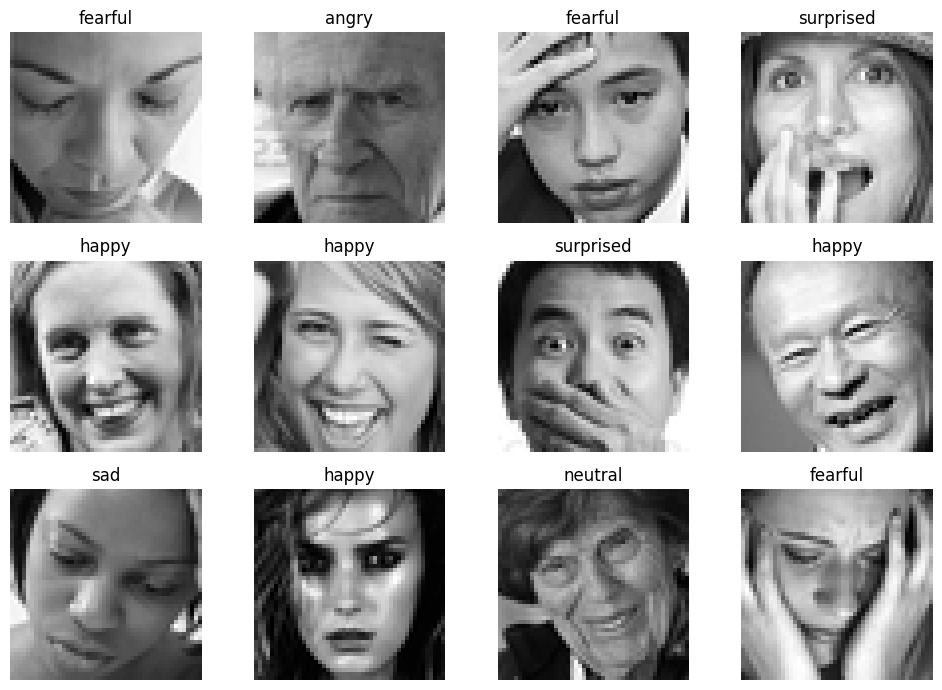

In [ ]:
plt.figure(figsize=(10, 7))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(tf.squeeze(images[i]), cmap="gray")
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.08),
], name="data_augmentation")

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(48, 48, 1)),
    data_augmentation,
    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.40),
    tf.keras.layers.Dense(num_classes, activation="softmax")
], name="face_emotion_cnn")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "face_emotion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,935 (2.61 MB)

 Trainable params: 684,231 (2.61 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
os.makedirs("models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "models/face_emotion_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 165s 460ms/step - accuracy: 0.5228 - loss: 1.2522 - val_accuracy: 0.5887 - val_loss: 1.1264 - learning_rate: 2.5000e-04
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 168s 467ms/step - accuracy: 0.5266 - loss: 1.2398 - val_accuracy: 0.6130 - val_loss: 1.0662 - learning_rate: 2.5000e-04
Epoch 3/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 206s 478ms/step - accuracy: 0.5368 - loss: 1.2225 - val_accuracy: 0.5971 - val_loss: 1.1286 - learning_rate: 2.5000e-04
Epoch 4/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 203s 480ms/step - accuracy: 0.5387 - loss: 1.2174 - val_accuracy: 0.5863 - val_loss: 1.1001 - learning_rate: 2.5000e-04
Epoch 5/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 209s 498ms/step - accuracy: 0.5477 - loss: 1.2023 - val_accuracy: 0.6116 - val_loss: 1.0620 - learning_rate: 2.5000e-04
Epoch 6/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 180s 502ms/step - accuracy: 0.5414 - loss: 1.2044 - val_accuracy: 0.6063 - val_loss: 1.1018 - learning_rate: 2.5000e-04
Epoch 7/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 

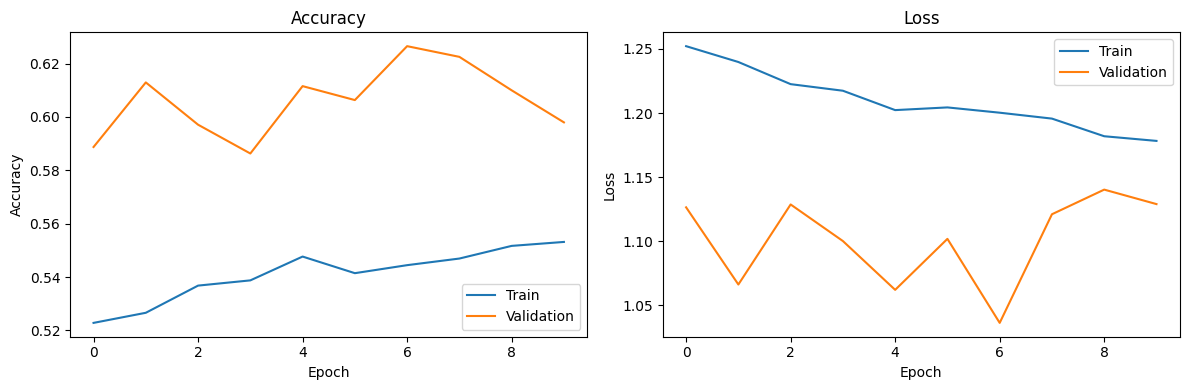

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 105ms/step - accuracy: 0.5702 - loss: 1.1366
Test loss     : 1.1366
Test accuracy : 0.5702


113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 101ms/step
              precision    recall  f1-score   support

       angry       0.43      0.57      0.49       958
   disgusted       0.58      0.17      0.26       111
     fearful       0.42      0.26      0.32      1024
       happy       0.82      0.78      0.80      1774
     neutral       0.51      0.58      0.54      1233
         sad       0.45      0.44      0.44      1247
   surprised       0.66      0.74      0.70       831

    accuracy                           0.57      7178
   macro avg       0.55      0.51      0.51      7178
weighted avg       0.57      0.57      0.56      7178



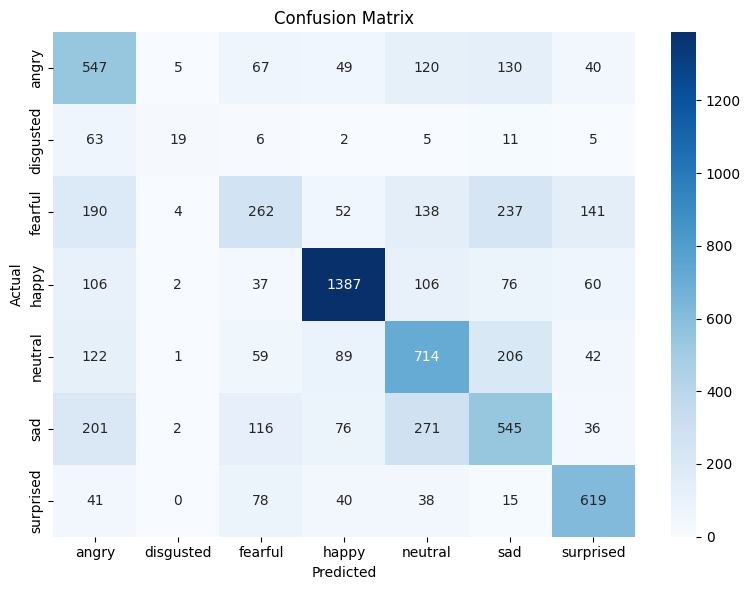

In [ ]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true, y_pred, target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
MODEL_PATH = "face_emotion_cnn.keras"
LABELS_PATH = "class_names.txt"

model.save(MODEL_PATH)
with open(LABELS_PATH, "w", encoding="utf-8") as f:
    f.write("\\n".join(class_names))

print("Model tersimpan:", MODEL_PATH)
print("Label tersimpan:", LABELS_PATH)

Model tersimpan: face_emotion_cnn.keras
Label tersimpan: class_names.txt


Saving images (1).jpg to images (1).jpg
Prediksi ekspresi: angry
Skor model: 61.98%


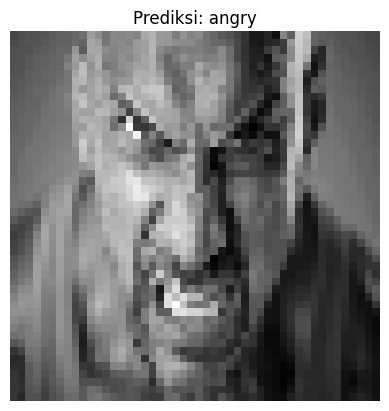

angry       : 61.98%
disgusted   : 0.39%
fearful     : 22.17%
happy       : 2.46%
neutral     : 1.23%
sad         : 7.83%
surprised   : 3.95%


In [ ]:
from google.colab import files
from PIL import Image

uploaded = files.upload()
image_path = next(iter(uploaded))

img = tf.keras.utils.load_img(
    image_path,
    color_mode="grayscale",
    target_size=IMG_SIZE
)
img_array = tf.keras.utils.img_to_array(img)
img_batch = np.expand_dims(img_array, axis=0)

probabilities = model.predict(img_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("Prediksi ekspresi:", class_names[predicted_index])
print("Skor model:", f"{probabilities[predicted_index] * 100:.2f}%")

plt.imshow(tf.squeeze(img_array), cmap="gray")
plt.title(f"Prediksi: {class_names[predicted_index]}")
plt.axis("off")
plt.show()

for name, score in zip(class_names, probabilities):
    print(f"{name:12s}: {score * 100:.2f}%")